# 1 — Préparer et explorer les alertes AIT-ADS

**But du notebook.** Transformer les journaux bruts de plusieurs détecteurs en une table d’événements homogène, puis rendre visible ce qu’elle contient avant de construire des liens entre alertes.

> Une ligne représente **une alerte**. Le prétraitement ne décide pas que deux alertes sont liées : il conserve le temps et le contexte nécessaires pour que le modèle puisse ensuite les comparer.

## Pourquoi ce jeu de données ?

Notre projet porte sur des **alertes IDS émises par des détecteurs**. AIT-ADS contient des alertes de plusieurs sources et des scénarios d’attaque en plusieurs phases, ce qui correspond mieux à la question de corrélation.

Nous utilisons `shaw` et `wardbeck` pour l’apprentissage, puis gardons `russellmitchell` pour un test par scénario. Les fenêtres d’attaque fournies sont des annotations temporelles : elles ne disent pas quelles paires d’alertes un analyste aurait reliées.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from html import escape
import sys
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path.cwd()
if not (ROOT / 'src' / 'alert_correlation').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from alert_correlation.core import preprocess_ait_ads, load_alerts, SCENARIOS

DATA = ROOT / 'data' / 'AIT-ADS'
OUT = ROOT / 'artifacts' / 'alert_correlation' / 'normalized_alerts.csv'
SCENARIOS_USED = ['shaw', 'wardbeck', 'russellmitchell']
assert (DATA / 'ait_ads.zip').exists(), 'Archive AIT-ADS introuvable'
assert (DATA / 'labels.csv').exists(), 'Fichier labels.csv introuvable'
print('Dossier du projet :', ROOT)
print('Scénarios retenus :', SCENARIOS_USED)

Dossier du projet : C:\Users\seife\Downloads\new_correlation_project
Scénarios retenus : ['shaw', 'wardbeck', 'russellmitchell']


## Étape 1 — Normaliser les journaux

Les sources n’emploient pas toutes les mêmes noms de champs ni le même format d’horodatage. La fonction les ramène à un format commun : identifiant, date, détecteur, hôte, signature, sévérité et message.

`attack_phase` et `is_attack` sont ajoutés à partir des intervalles de `labels.csv`. Ils servent à construire un **label faible** lors de la validation. Ils ne doivent pas être présentés comme une décision humaine sur le lien entre deux alertes.

In [2]:
counts = preprocess_ait_ads(
    DATA / 'ait_ads.zip',
    DATA / 'labels.csv',
    OUT,
    scenarios=SCENARIOS_USED,
)
alerts = load_alerts(OUT)
print('Fichier écrit :', OUT.relative_to(ROOT))
print('Nombre total d’alertes normalisées :', len(alerts))

def show_table(headers, body):
    head = ''.join(f'<th>{escape(str(h))}</th>' for h in headers)
    rows = ''.join('<tr>' + ''.join(f'<td>{escape(str(v))}</td>' for v in row) + '</tr>' for row in body)
    display(HTML(f'<table><thead><tr>{head}</tr></thead><tbody>{rows}</tbody></table>'))

show_table(
    ['Scénario', 'Alertes', 'Alertes dans une fenêtre de phase'],
    [[scenario, values['alerts'], values['attack_phase']] for scenario, values in counts.items()]
)

Fichier écrit : artifacts\alert_correlation\normalized_alerts.csv
Nombre total d’alertes normalisées : 207583


Scénario,Alertes,Alertes dans une fenêtre de phase
shaw,70782,6935
wardbeck,91257,7040
russellmitchell,45544,12015


## Étape 2 — Voir la composition des données

Le premier graphique sépare, pour chaque scénario, les alertes qui tombent dans une fenêtre de phase et celles qui sont hors de ces fenêtres. Le second montre les volumes par détecteur. Les catégories « dans une phase » ne sont qu’un repère temporel ; elles ne signifient pas que chaque alerte est vraie ou malveillante.

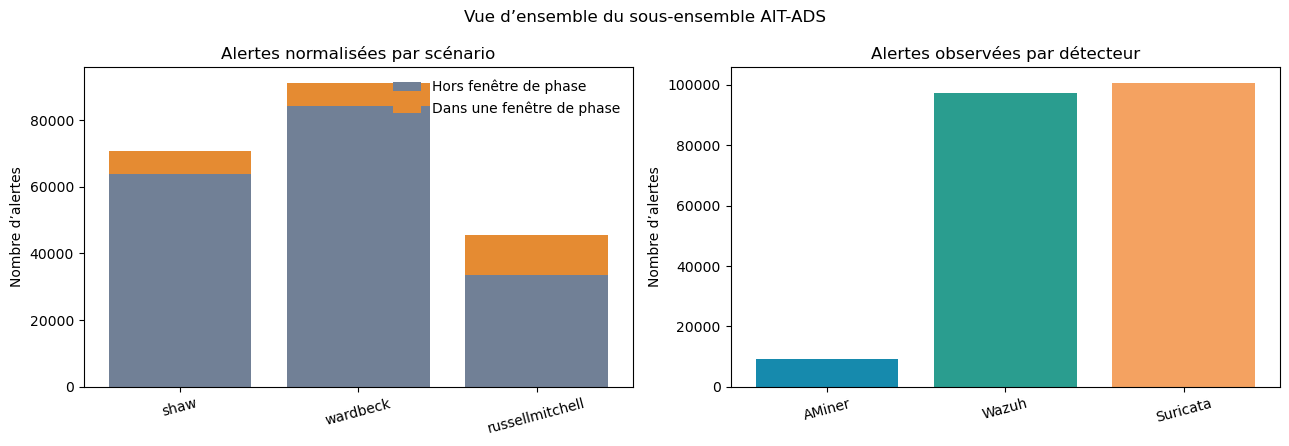

Détecteur,Alertes
AMiner,9352
Suricata,100792
Wazuh,97439


In [3]:
scenario_order = [s for s in SCENARIOS_USED if s in counts]
inside = [counts[s]['attack_phase'] for s in scenario_order]
outside = [counts[s]['alerts'] - counts[s]['attack_phase'] for s in scenario_order]
detector_counts = Counter(a['detector'] for a in alerts)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(scenario_order, outside, label='Hors fenêtre de phase', color='#718096')
axes[0].bar(scenario_order, inside, bottom=outside, label='Dans une fenêtre de phase', color='#e58b32')
axes[0].set_title('Alertes normalisées par scénario')
axes[0].set_ylabel('Nombre d’alertes')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(frameon=False)
axes[1].bar(list(detector_counts), list(detector_counts.values()), color=['#168aad', '#2a9d8f', '#f4a261'][:len(detector_counts)])
axes[1].set_title('Alertes observées par détecteur')
axes[1].set_ylabel('Nombre d’alertes')
axes[1].tick_params(axis='x', rotation=15)
fig.suptitle('Vue d’ensemble du sous-ensemble AIT-ADS')
fig.tight_layout()
plt.show()

show_table(['Détecteur', 'Alertes'], sorted(detector_counts.items()))

## Étape 3 — Observer le temps et les champs normalisés

La corrélation dépend de l’ordre : une alerte entrante est comparée à des alertes antérieures du même scénario, dans une fenêtre maximale de 30 minutes. Le graphique ci-dessous rend le rythme des alertes visible, sans supposer qu’un pic représente forcément une attaque.

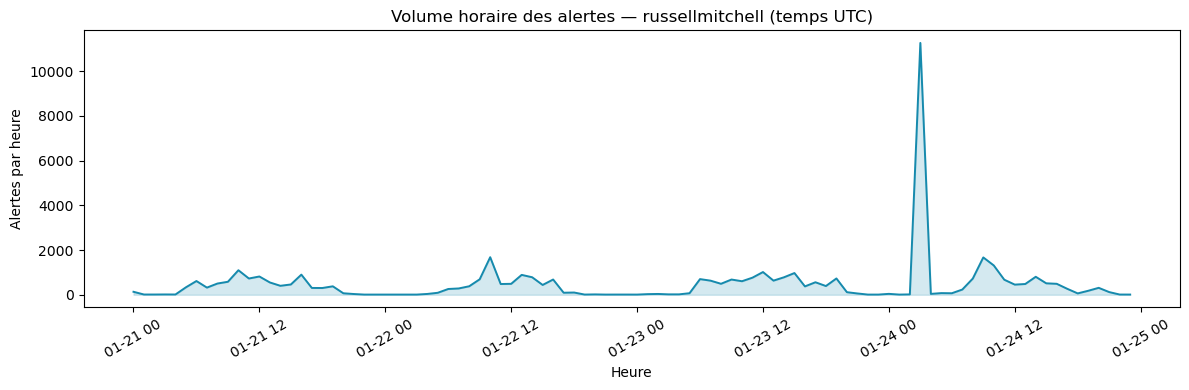

Champ,Interprétation
timestamp_epoch,Temps numérique utilisé pour trier et calculer les écarts
detector,Source qui a produit l’alerte
host,"Hôte concerné, quand la source le fournit"
signature,Règle ou type d’événement rapporté
attack_phase / is_attack,"Fenêtre de phase issue du dataset ; label faible, pas lien expert"


In [4]:
test_scenario = 'russellmitchell'
hourly = Counter()
for alert in alerts:
    if alert['scenario'] == test_scenario:
        hour = datetime.fromtimestamp(alert['timestamp_epoch'], timezone.utc).replace(minute=0, second=0, microsecond=0)
        hourly[hour] += 1

hours = sorted(hourly)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hours, [hourly[h] for h in hours], color='#168aad', linewidth=1.4)
ax.fill_between(hours, [hourly[h] for h in hours], color='#168aad', alpha=.18)
ax.set_title(f'Volume horaire des alertes — {test_scenario} (temps UTC)')
ax.set_ylabel('Alertes par heure')
ax.set_xlabel('Heure')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
plt.show()

show_table(
    ['Champ', 'Interprétation'],
    [
        ['timestamp_epoch', 'Temps numérique utilisé pour trier et calculer les écarts'],
        ['detector', 'Source qui a produit l’alerte'],
        ['host', 'Hôte concerné, quand la source le fournit'],
        ['signature', 'Règle ou type d’événement rapporté'],
        ['attack_phase / is_attack', 'Fenêtre de phase issue du dataset ; label faible, pas lien expert'],
    ]
)

## Contrat transmis au modèle

Le fichier `artifacts/alert_correlation/normalized_alerts.csv` contient une ligne par alerte. Le notebook suivant trie les événements par scénario et par date, construit des paires candidates à partir de l’historique, puis compare ces paires avec quelques indices observables.

**À retenir :** le prétraitement rassemble les champs ; la corrélation et l’évaluation viennent après.